# EDA Notebook

This notebook contains EDA associated with the FPL email report

## Momentum Plots

In [6]:
import sys
import os

# Add the src folder to the Python path
src_path = os.path.abspath(os.path.join('.', 'src'))
sys.path.append(src_path)

# Import the engineer_features function
from data_sourcing import fetch_fpl_data
from feature_engineering import engineer_features

df = fetch_fpl_data()

INFO:root:Fetching FPL data.
100%|██████████| 756/756 [00:18<00:00, 39.94it/s]


In [7]:
import pandas as pd
pd.set_option('display.max_columns', None)
df.head()

,id_player,web_name,chance_of_playing_next_round,element_type,now_cost,team_code,code,team_name,id_pos,player_position,squad_select,element,total_points,round
0,1,Fábio Vieira,0.0,3,54,3,3,Arsenal,3,MID,5,1,0,1
1,1,Fábio Vieira,0.0,3,54,3,3,Arsenal,3,MID,5,1,0,2
2,1,Fábio Vieira,0.0,3,54,3,3,Arsenal,3,MID,5,1,0,3
3,1,Fábio Vieira,0.0,3,54,3,3,Arsenal,3,MID,5,1,0,4
4,1,Fábio Vieira,0.0,3,54,3,3,Arsenal,3,MID,5,1,0,5


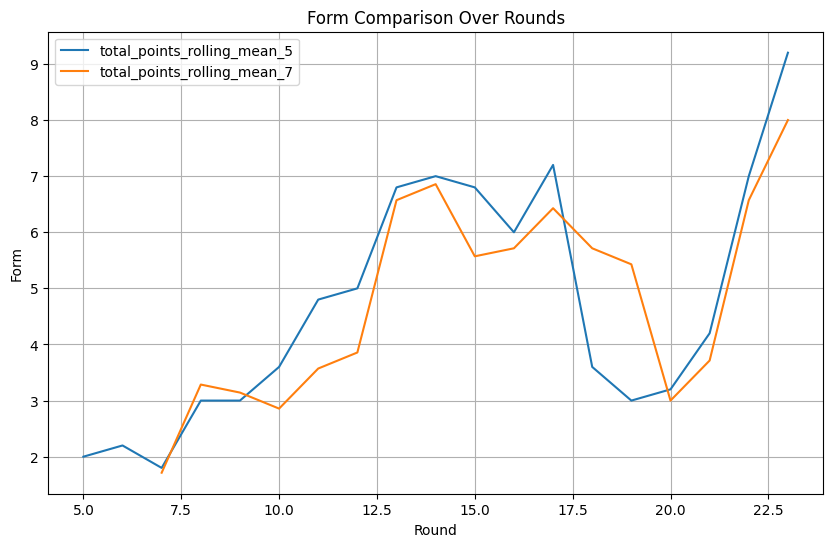

In [2]:
from feature_engineering import calc_rolling_mean
import matplotlib.pyplot as plt
import seaborn as sns

def plot_momentum(df, player_id, short_period=3, long_period=7):
    # calculate short and long period forms
    base_col = 'total_points'
    short_period_col_name = f'{base_col}_rolling_mean_{short_period}'
    long_period_col_name = f'{base_col}_rolling_mean_{long_period}'

    df = calc_rolling_mean(df, base_col, short_period)
    df = calc_rolling_mean(df, base_col, long_period)

    df_temp = df[df['id_player'] == player_id][['round', short_period_col_name, long_period_col_name]].drop_duplicates().reset_index()

    # Plotting with seaborn
    plt.figure(figsize=(10, 6))
    sns.lineplot(data=df_temp, x="round", y=short_period_col_name, label=short_period_col_name)
    sns.lineplot(data=df_temp, x="round", y=long_period_col_name, label=long_period_col_name)
    plt.title("Form Comparison Over Rounds")
    plt.xlabel("Round")
    plt.ylabel("Form")
    plt.legend()
    plt.grid(True)
    plt.show()

    return df

df = plot_momentum(df, player_id=71, short_period=5, long_period=7)

In [3]:
df[df['id_player'] == 71]

,id_player,web_name,chance_of_playing_next_round,element_type,now_cost,team_code,code,team_name,id_pos,player_position,squad_select,element,total_points,round,mean_ppg_3,total_points_rolling_mean_5,total_points_rolling_mean_7
1852,71,Kluivert,100.0,3,57,91,91,Bournemouth,3,MID,5,71,0,1,14.333333,NaN,NaN
1853,71,Kluivert,100.0,3,57,91,91,Bournemouth,3,MID,5,71,3,2,14.333333,NaN,NaN
1854,71,Kluivert,100.0,3,57,91,91,Bournemouth,3,MID,5,71,5,3,14.333333,NaN,NaN
1855,71,Kluivert,100.0,3,57,91,91,Bournemouth,3,MID,5,71,2,4,14.333333,NaN,NaN
1856,71,Kluivert,100.0,3,57,91,91,Bournemouth,3,MID,5,71,0,5,14.333333,2.0,NaN
1857,71,Kluivert,100.0,3,57,91,91,Bournemouth,3,MID,5,71,1,6,14.333333,2.2,NaN
1858,71,Kluivert,100.0,3,57,91,91,Bournemouth,3,MID,5,71,1,7,14.333333,1.8,1.714286
1859,71,Kluivert,100.0,3,57,91,91,Bournemouth,3,MID,5,71,11,8,14.333333,3.0,3.285714
1860,71,Kluivert,100.0,3,57,91,91,Bournemouth,3,MID,5,71,2,9,14.333333,3.0,3.142857
1861,71,Kluivert,100.0,3,57,91,91,Bournemouth,3,MID,5,71,3,10,14.333333,3.6,2.857143
